In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from amms.core import products
from amms.core.analysis.sfr import lookback_edges, sfh, sfr_map_from_young_stars
from amms.core.datasets import b12, patel2020
from amms.core.analysis import units
from amms.core.plotting.maps import shared_norm, show_map

DATASET, DT = "ext_b12-model2", 0.01 # kpc, Gyr
MAP_DT = 0.1
LMC_R_MAX = 5.0
SMC_R_MAX = 2.0

# Loading functions

In [ ]:
def load_maps(galaxy, snap=69, dt=MAP_DT, bins=40):
    p = products.read_product(products.product_path(DATASET, "newstars", f"{galaxy}-{snap:03d}"))
    age = p.attrs.meta["t_now_gyr"] - p.arrays["t_form_gyr"]
    return [sfr_map_from_young_stars(p.arrays["pos_kpc"], p.arrays["mass_msun"], age, dt=dt,
                                     axes=ax, extent=GAL[galaxy]["extent"], bins=bins)
            for ax in ("xy", "xz")]

In [26]:
def load_sfh(galaxy, snap=69, r_max=LMC_R_MAX, dt=DT):
    p = products.read_product(products.product_path(DATASET, "newstars", f"{galaxy}-{snap:03d}"))
    t_now = p.attrs.meta["t_now_gyr"]
    edges = lookback_edges(t_now, dt)
    pos, t, m = p.arrays["pos_kpc"], p.arrays["t_form_gyr"], p.arrays["mass_msun"]
    sel = np.linalg.norm(pos, axis=1) < r_max # position is already in the galaxy's own frame
    _, rate = sfh(t[sel], m[sel], bins=edges)
    _, rate_all = sfh(t, m, bins=edges)
    return p, t_now, edges, rate, rate_all

In [ ]:
def load_orbits(model):
    ds = f"ext_b12-model{model}"
    o = {g: products.read_product(products.product_path(ds, "orbit", g)).arrays for g in ("lmc", "smc")}
    assert np.array_equal(o["lmc"]["snapshot"], o["smc"]["snapshot"])
    # present day taken from the same header that the newstars product used
    # SFH and orbit panels then share t_now
    t_now = float(o["lmc"]["t_gyr"][o["lmc"]["snapshot"] == b12.SNAP_PRESENT_DAY][0])
    return o, t_now

## SFR + SFH

In [ ]:
GAL = {"lmc": {"r_max": LMC_R_MAX, "extent": 10.0},
       "smc": {"r_max": SMC_R_MAX, "extent": 5.0}}


In [ ]:
fig, axd = plt.subplot_mosaic("AB;CD;EF", figsize=(9.5, 11), constrained_layout=True,
                              gridspec_kw={"height_ratios": [1, 1, 0.7]})

# Rows 1-2 are the SFR maps
for galaxy, (kf, ke) in (("lmc", "AB"), ("smc", "CD")):
    maps = load_maps(galaxy)
    norm = shared_norm(maps, percentiles=(1, 99.5), min_counts=3)
    for k, m, view in ((kf, maps[0], "face-on"), (ke, maps[1], "edge-on")):
        im = show_map(m, axd[k], norm=norm, min_counts=3, cmap="inferno", cbar=False)
        axd[k].set_title(f"{galaxy.upper()} {view} ($\\Delta t$ = {MAP_DT*1e3:.0f} Myr), n={m.meta['n_young']}")
    fig.colorbar(im, ax=[axd[kf], axd[ke]], label=r"%\Sigma_{\rm SFR}$ [M_$\odot$ yr$^{-1}$ kpc$^{-2}$]")

# Row3 is the SFH
for galaxy, k in (("lmc", "E"), ("smc", "F")):
    r_max = GAL[galaxy]["r_max"]
    _, t_now, edges, rate, rate_all = load_sfh(galaxy, r_max=r_max)
    lb = (t_now - edges)[::-1] # reversed and stairs get increasing lookback from 0 = present day 
    axd[k].stairs(rate[::-1], lb, label=f"r < {r_max:g} kpc")
    axd[k].stairs(rate_all[::-1], lb, ls="--", label=f"all {galaxy.upper()}")
    axd[k].set(xlabel="lookback time [Gyr]", xlim=(0, 1), title=f"{galaxy.upper()} SFH ({DT*1e3:.0f} Myr bins)")
    axd[k].legend(fontsize=7)
axd["E"].set_ylabel(r"SFR [$M_\odot\,\mathrm{yr}^{-1}$]")
fig.suptitle(f"{DATASET}, snapshot {b12.SNAP_PRESENT_DAY:03d}")

## Orbits

In [32]:
for model in (2, 1):
    o, t_now = load_orbits(model)
    for g, a in o.items():
        v_fd = np.linalg.norm(np.diff(a["pos_kpc"], axis=0), axis=1) / np.diff(a["t_gyr"]) / units.KPC_PER_GYR_PER_KMS
        speed = np.linalg.norm(a["vel_kms"], axis=1)
        ratio = v_fd / (0.5 * (speed[1:] + speed[:-1]))
        worst = int(np.argmax(np.abs(ratio - 1)))
        print(f"M{model} {g}: ratio {ratio.min():.3f}-{ratio.max():.3f}, worst at snap {a['snapshot'][worst + 1]}")

M2 lmc: ratio 0.953-1.048, worst at snap 5
M2 smc: ratio 0.939-1.047, worst at snap 16
M1 lmc: ratio 0.972-1.038, worst at snap 36
M1 smc: ratio 0.913-1.053, worst at snap 5


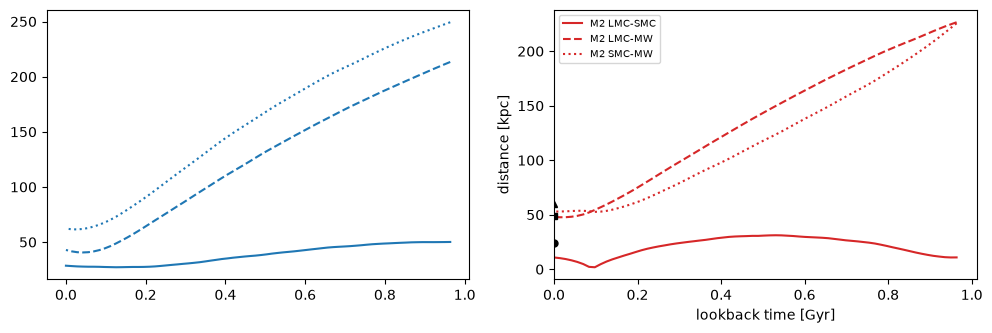

In [ ]:
COLOR= {1: "C0", 2: "C3"}
MODELS = (1, 2)

fig, axes = plt.subplots(1, len(MODELS), figsize=(12, 3.5))
for i, model in enumerate(MODELS):
    ax = axes[i]
    o, t_now = load_orbits(model)
    lmc, smc = o["lmc"], o["smc"]
    lb = t_now - lmc["t_gyr"]
    keep = lb >= -1e-9 # only keep up to present day
    c = COLOR[model]
    ax.plot(lb[keep], np.linalg.norm(lmc["pos_kpc"] - smc["pos_kpc"], axis=1)[keep], c=c, label=f"M{model} LMC-SMC")
    ax.plot(lb[keep], np.linalg.norm(lmc["pos_kpc"], axis=1)[keep], c=c, ls="--", label=f"M{model} LMC-MW")
    ax.plot(lb[keep], np.linalg.norm(smc["pos_kpc"], axis=1)[keep], c=c, ls=":", label=f"M{model} SMC-MW")

# Add in the present day location from Patel+2020 at lookback=0
L, S = np.asarray(patel2020.LMC_CENTER), np.asarray(patel2020.SMC_CENTER)
for d, mk in ((np.linalg.norm(L - S), "o"), (np.linalg.norm(L), "s"), (np.linalg.norm(S), "^")):
    ax.plot(0, d, mk, c="k", ms=5)
    ax.set(xlabel="lookback time [Gyr]", ylabel="distance [kpc]", xlim=(0, None))
    ax.legend(fontsize=7)
# ax.invert_xaxis()